## Different post-processing Deseasonalization ##  
Berechne für den Gesamtzeitraum (1979-2023) den klimatologischen mean (per day of the year). Dann glätte dieses MIttel mit dem rolling mean (30 Tage). Subtrahiere das klimatologische Mittel von den normalen daily data. Erhalte so die Anomalie der Zeitreihe.

In [1]:
import xarray as xr
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
ATM_NAME = "relative_humidity"
LEVEL = "700"

BASE_PATH = Path("data/ERA5/")
INPUT_PATH = BASE_PATH / f"{ATM_NAME}{LEVEL}"
OUTPUT_PATH = BASE_PATH / f"prepared/DJF_anom/{ATM_NAME}{LEVEL}"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

files = sorted(INPUT_PATH.glob("era5_daily_*.nc"))
years = sorted(list(set([f.name.split("_")[-1][:4] for f in files])))

print("[INFO] Years:", years)

# -----------------------------------
# 1. GLOBALE KLIMATOLOGIE BERECHNEN
# -----------------------------------
print("[INFO] Computing climatology...")

ds_all = xr.open_mfdataset(
    files,
    combine="by_coords",
    chunks={"time": -1}
).sortby("time")

# Mittelwert pro Kalendertag
clim = ds_all.groupby("time.dayofyear").mean("time")

# 30-Tage-Glättung der Klimatologie
clim_smooth = clim.rolling(
    dayofyear=30,
    center=True,
    min_periods=15
).mean()

ds_all.close()
del ds_all

[INFO] Years: ['1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022']
[INFO] Computing climatology...


In [3]:
print(clim_smooth)

<xarray.Dataset> Size: 237MB
Dimensions:            (latitude: 289, longitude: 561, dayofyear: 366)
Coordinates:
  * latitude           (latitude) float32 1kB 84.0 83.75 83.5 ... 12.25 12.0
  * longitude          (longitude) float32 2kB 270.0 270.2 270.5 ... 49.75 50.0
  * dayofyear          (dayofyear) int64 3kB 1 2 3 4 5 6 ... 362 363 364 365 366
    level              int64 8B 700
Data variables:
    relative_humidity  (dayofyear, latitude, longitude) float32 237MB dask.array<chunksize=(30, 9, 17), meta=np.ndarray>


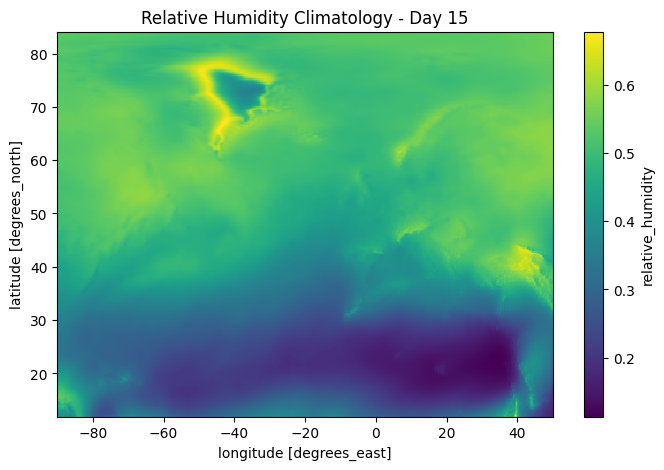

In [4]:
da = clim_smooth["relative_humidity"].isel(dayofyear=15)
da = da.assign_coords(
    longitude=((da.longitude + 180) % 360) - 180
).sortby("longitude")
# plot
plt.figure(figsize=(8,5))
da.plot()
plt.title("Relative Humidity Climatology - Day 15")
plt.show()

In [7]:
# -----------------------------------
#  LOOP ÜBER JAHRE
# -----------------------------------
years_i = ['1980', '1981']
for i, year in enumerate(years_i):

    print(f"[INFO] Processing year {year}")

    # -----------------------------------
    # 2-3 Jahres Fenster 
    # -----------------------------------
    if i == 0:
        sel_years = [years[i], years[i+1]]
    elif i == len(years)-1:
        sel_years = [years[i-1], years[i]]
    else:
        sel_years = [years[i-1], years[i], years[i+1]]

    year_files = [
        f for f in files
        if any(y in f.name for y in sel_years)
    ]

    ds = xr.open_mfdataset(
        year_files,
        combine="by_coords",
        chunks={"time": -1, "latitude": 50, "longitude": 50}
    ).sortby("time")

    # -----------------------------------
    # 2. ANOMALIEN BERECHNEN
    # -----------------------------------
    ds_anom = ds.groupby("time.dayofyear") - clim_smooth

    # -----------------------------------
    # DJF extrahieren
    # -----------------------------------
    ds_djf = ds_anom.sel(
        time=ds_anom.time.dt.month.isin([12, 1, 2])
    )

    ds_djf = ds_djf.sel(time=ds_djf.time.dt.year == int(year))

    # -----------------------------------
    # speichern
    # -----------------------------------
    out_file = OUTPUT_PATH / f"{ATM_NAME}_{year}_DJF_anom.nc"

    VAR_NAME = 'relative_humidity'

    ds_djf.to_netcdf(
        out_file,
        encoding={f'{VAR_NAME}': {"zlib": True, "complevel": 4}}
    )

    ds.close()
    del ds, ds_anom, ds_djf

print("[INFO] DONE")

[INFO] Processing year 1980
[INFO] Processing year 1981
[INFO] DONE


In [8]:
df = xr.open_dataset(f"{OUTPUT_PATH}/{ATM_NAME}_{years_i[0]}_DJF_anom.nc")

In [10]:
df['level'].values

array([700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700,
       700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700,
       700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700,
       700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700,
       700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700,
       700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700,
       700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700, 700])

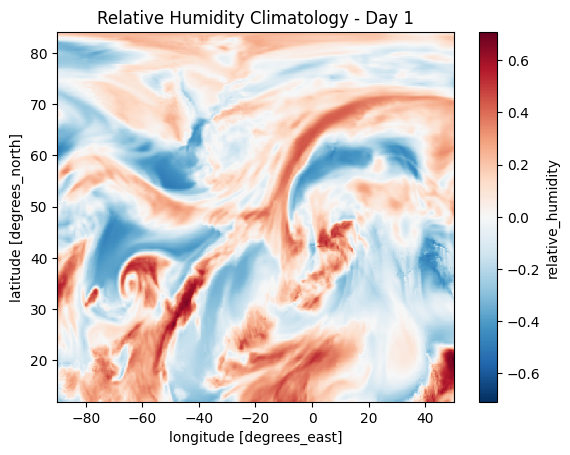

In [ ]:
df = df.assign_coords(
    longitude=((df.longitude + 180) % 360) - 180
).sortby("longitude")
# ersten Tag plotten
da = df.relative_humidity.isel(time=80)
da.plot()
plt.title("Relative Humidity Climatology - Day 1")
plt.show()

In [ ]:
df2 = xr.open_dataset(f"data/ERA5/prepared/DJF_new/{ATM_NAME}/{ATM_NAME}_{years[0]}_DJF_rm.nc")

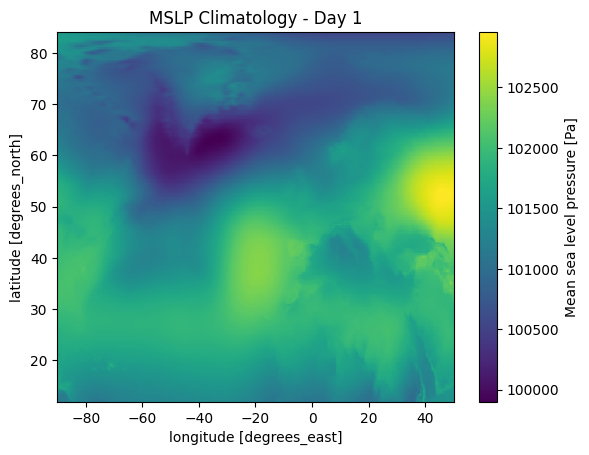

In [ ]:
df2 = df2.assign_coords(
    longitude=((df.longitude + 180) % 360) - 180
).sortby("longitude")
# ersten Tag plotten
da = df2.mean_sea_level_pressure.isel(time=0)
da.plot()
plt.title("MSLP Climatology - Day 1")
plt.show()